In [1]:
import matplotlib.pyplot as plt
import pickle
import pandas as pd
import numpy as np
import json, glob

In [2]:
# yalan data

# # all years
# inpath = '/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan'

# with open(f'{inpath}/training_file', 'rb') as f:
#     forcing_train, target_train, attr_train = pickle.load(f)

# AllTime = pd.date_range('1980-10-01', f'2014-09-30', freq='d')

# gage_camels = np.load(f"{inpath}/gageid.npy")


inpath = '/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan'

with open(f'{inpath}/training_file', 'rb') as f:
    forcing_train, target_train, attr_train = pickle.load(f)

AllTime = pd.date_range('1980-10-01', f'2014-09-30', freq='d')

gage_camels = np.load(f"{inpath}/gageid.npy")

subsetPath = f'{inpath}/Sub531ID.txt'
with open(subsetPath, 'r') as fp:
     selected_camels = json.load(fp)

# wrong method
# [C, Ind, SubInd] = np.intersect1d(selected_camels, gage_camels, return_indices=True)

SubInd = []
for i in selected_camels:
    SubInd.append(np.squeeze(np.where(gage_camels==i)))


startYear =1999
endYear = 2008
newTime = pd.date_range(f'{startYear}-10-01', f'{endYear}-09-30', freq='d')

index_start = AllTime.get_loc(newTime[0])
index_end = AllTime.get_loc(newTime[-1]) + 1

forcing_train = forcing_train[SubInd,index_start:index_end]
target_train = target_train[SubInd,index_start:index_end]

In [3]:
# load camels P
Pcamels = []
for b in range(len(selected_camels)):
    file_path = glob.glob(f"/glade/campaign/cgd/tss/people/guoqiang/camels/obs_flow_met/basin_dataset_public_v1p2/basin_mean_forcing/daymet/*/{selected_camels[b]:08}_lump_cida_forcing_leap.txt")[0]
    data = pd.read_csv(file_path, sep='\s+', skiprows=4, header=None)
    data.columns = ["Year", "Month", "Day", "Hr", "dayl(s)", "prcp(mm/day)", "srad(W/m2)", 
                    "swe(mm)", "tmax(C)", "tmin(C)", "vp(Pa)"]
    data['Date'] = pd.to_datetime(data[['Year', 'Month', 'Day']])
    # start_date = '1980-10-01'
    # end_date = '2014-09-30'
    start_date = '1999-10-01'
    end_date = '2008-09-30'
    filtered_data = data[(data['Date'] >= start_date) & (data['Date'] <= end_date)]
    filtered_data = filtered_data.drop(columns=['Date'])
    Pcamels.append(filtered_data['prcp(mm/day)'].values)

Pcamels = np.array(Pcamels)

In [4]:
# load CAMELS Q
Qcamels = []

for b in range(len(selected_camels)):
    file_path = f'/glade/campaign/cgd/tss/people/guoqiang/camels/obs_flow_met/basin_dataset_public_v1p2/usgs_streamflow/all/{selected_camels[b]:08}_streamflow_qc.txt'
    data = pd.read_csv(file_path, sep='\s+',  header=None)
    data.columns = ["ID", "Year", "Month", "Day", "Q", "QC"]
    data['Date'] = pd.to_datetime(data[['Year', 'Month', 'Day']])
    start_date = '1999-10-01'
    end_date = '2008-09-30'
    filtered_data = data[(data['Date'] >= start_date) & (data['Date'] <= end_date)]
    filtered_data = filtered_data.drop(columns=['Date'])
    Qcamels.append(filtered_data['Q'].values)

Qcamels = np.array(Qcamels)

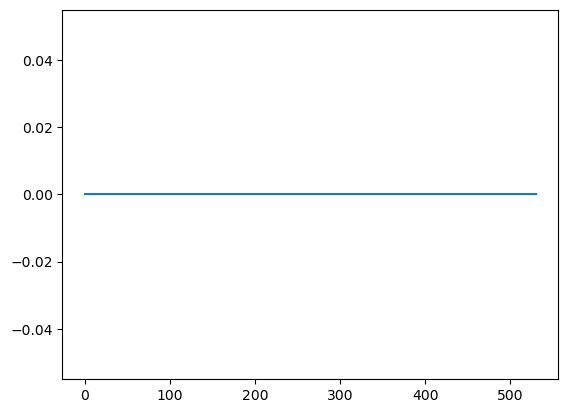

In [5]:
# compare
diff = forcing_train[:,:,0] - Pcamels
diffm = np.nanmean(np.abs(diff), axis=1)
plt.plot(diffm)

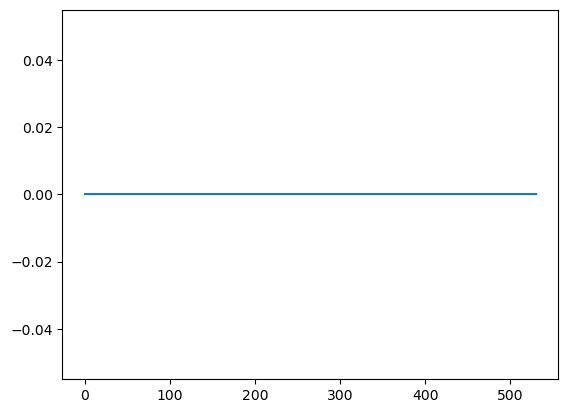

In [6]:
diff = target_train[:,:,0] - Qcamels
diffm = np.nanmean(np.abs(diff), axis=1)
plt.plot(diffm)